In [1]:
import pandas as pd
import json                                                     # 추가

ko = pd.read_csv('data/processed/ko/processed_ko.csv')          # 경로 변경
ko = ko.dropna(subset=['tokens'])
texts_ko = ko['tokens'].apply(json.loads).tolist()              # str.split() → json.loads

In [2]:
from gensim.corpora.dictionary import Dictionary

dictionary = Dictionary(texts_ko)
print('#Number of initial unique words in documents:', len(dictionary))

dictionary.filter_extremes(keep_n = None, no_below=2, no_above=0.5)
print('#Number of unique words after removing rare and common words:', len(dictionary))

corpus = [dictionary.doc2bow(text) for text in texts_ko]
print('#Number of unique tokens: %d' % len(dictionary))
print('#Number of documents: %d' % len(corpus))

#Number of initial unique words in documents: 3369
#Number of unique words after removing rare and common words: 3368
#Number of unique tokens: 3368
#Number of documents: 1086


In [3]:
from gensim.models import LdaModel

num_topics = 7
passes = 5
%time model = LdaModel(corpus=corpus, id2word=dictionary,\
                       passes=passes, num_topics=num_topics, \
                       random_state=7)

CPU times: total: 6.58 s
Wall time: 10.4 s


In [4]:
model.print_topics(num_words=10)

[(0,
  '0.029*"일정" + 0.024*"인천국제공항" + 0.024*"오후" + 0.022*"중구" + 0.022*"출국" + 0.018*"해외" + 0.018*"입국" + 0.017*"가수" + 0.014*"참석" + 0.012*"패션"'),
 (1,
  '0.025*"일본" + 0.019*"무대" + 0.019*"공연" + 0.016*"팬" + 0.014*"콘서트" + 0.009*"데뷔" + 0.009*"투어" + 0.008*"관객" + 0.007*"현지" + 0.007*"음악"'),
 (2,
  '0.022*"서울" + 0.009*"로라" + 0.009*"오후" + 0.009*"아현" + 0.008*"파리타" + 0.008*"아사" + 0.007*"팬" + 0.007*"공개" + 0.007*"민규" + 0.007*"치키타"'),
 (3,
  '0.028*"브랜드" + 0.017*"지수" + 0.015*"분석" + 0.014*"그룹" + 0.014*"평판" + 0.012*"아티스트" + 0.007*"가수" + 0.006*"소속사" + 0.006*"팬" + 0.006*"공식"'),
 (4,
  '0.011*"앨범" + 0.011*"그룹" + 0.010*"무대" + 0.009*"음악" + 0.009*"미국" + 0.009*"차트" + 0.008*"공연" + 0.008*"팬" + 0.007*"빌보드" + 0.007*"발매"'),
 (5,
  '0.019*"곡" + 0.018*"앨범" + 0.017*"차트" + 0.011*"뮤직비디오" + 0.010*"데뷔" + 0.010*"공개" + 0.009*"그룹" + 0.008*"기록" + 0.008*"팬" + 0.008*"발매"'),
 (6,
  '0.018*"와이지엔터테인먼트" + 0.015*"공개" + 0.014*"팬" + 0.011*"제니" + 0.010*"공식" + 0.009*"그룹" + 0.007*"모습" + 0.007*"무대" + 0.007*"속" + 0.007*"매력"')]

In [5]:
print("#topic distribution of the first document: ", model.get_document_topics(corpus)[0])

#topic distribution of the first document:  [(4, 0.99708503)]


In [6]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
pyLDAvis.enable_notebook()

lda_viz = gensimvis.prepare(model, corpus, dictionary)
lda_viz

c:\Users\user\Desktop\학교\.venv\lib\site-packages\pyLDAvis\_prepare.py:246: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  default_term_info = default_term_info.sort_values(


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
5      0.094710  0.078938       1        1  29.470945
4      0.074813  0.021618       2        1  17.355323
6      0.038783  0.036599       3        1  14.299655
3      0.043958 -0.190457       4        1  14.245321
1      0.082028  0.017834       5        1  10.359652
0     -0.275055  0.006963       6        1   8.706978
2     -0.059238  0.028504       7        1   5.562128, topic_info=        Term        Freq       Total Category  logprob  loglift
209      브랜드  420.000000  420.000000  Default  30.0000  30.0000
464       일정  319.000000  319.000000  Default  29.0000  29.0000
825   인천국제공항  206.000000  206.000000  Default  28.0000  28.0000
459       오후  460.000000  460.000000  Default  27.0000  27.0000
506       중구  188.000000  188.000000  Default  26.0000  26.0000
...      ...         ...         ...      ...      ...      ...
1081       춤   19.905515  139.441393   Topic7  -5.5674   0.9425
292       일본   22.004115  562.412134   Topic7  -5.4672  -0.3518
0         가수   21.068531  376.708548   Topic7  -5.5106   0.0055
168       투어   20.403033  298.391100   Topic7  -5.5427   0.2065
22        그룹   20.870886  804.535424   Topic7  -5.5200  -0.7627

[537 rows x 6 columns], token_table=      Topic      Freq  Term
term                       
3292      5  0.745158   가까이
3324      3  0.139516    가나
3324      5  0.837095    가나
0         1  0.082292    가수
0         2  0.156620    가수
...     ...       ...   ...
794       5  0.016885    후보
794       7  0.016885    후보
2121      1  0.164272    훈련
2121      5  0.657087    훈련
3167      5  0.782824  히로시마

[1714 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[6, 5, 7, 4, 2, 1, 3])

In [7]:
from gensim.models import CoherenceModel

cm = CoherenceModel(model=model, corpus=corpus, coherence='u_mass')
coherence = cm.get_coherence()
print(coherence)

-2.1717217367210724


In [8]:
import matplotlib.pyplot as plt
%matplotlib inline

num_topics: 2, perplexity: -7.472, coherence: -1.236
num_topics: 3, perplexity: -7.506, coherence: -1.251
num_topics: 4, perplexity: -7.488, coherence: -1.885
num_topics: 5, perplexity: -7.511, coherence: -2.627
num_topics: 6, perplexity: -7.539, coherence: -3.363
num_topics: 7, perplexity: -7.553, coherence: -2.892
num_topics: 8, perplexity: -7.568, coherence: -3.488
num_topics: 9, perplexity: -7.620, coherence: -3.275
num_topics: 10, perplexity: -7.652, coherence: -2.878
num_topics: 11, perplexity: -7.693, coherence: -3.164
num_topics: 12, perplexity: -7.739, coherence: -2.689
num_topics: 13, perplexity: -7.761, coherence: -3.125
num_topics: 14, perplexity: -7.785, coherence: -2.991
num_topics: 15, perplexity: -7.828, coherence: -3.134


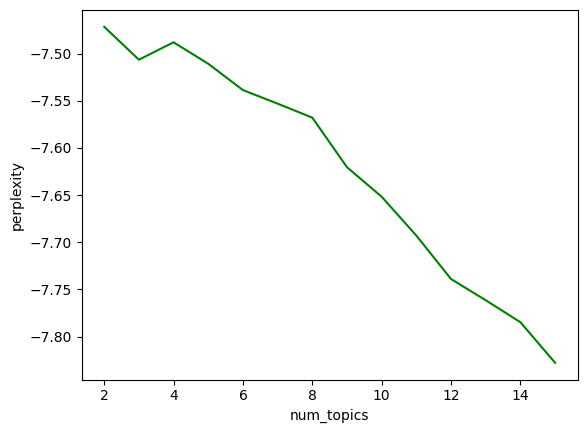

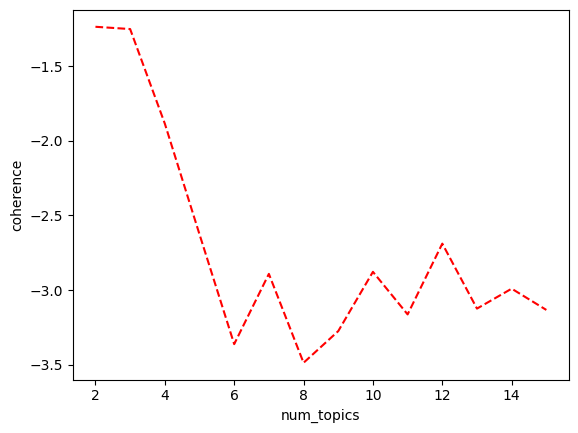

In [9]:
def show_coherence(corpus, dictionary, start=6, end=15):
    iter_num = []
    per_value = []
    coh_value = []

    for i in range(start, end + 1):
        model = LdaModel(corpus=corpus, id2word=dictionary,
                         chunksize=1000, num_topics=i,
                         random_state=7)
        iter_num.append(i)
        pv = model.log_perplexity(corpus)
        per_value.append(pv)

        cm = CoherenceModel(model=model, corpus=corpus,
                            coherence='u_mass')
        cv = cm.get_coherence()
        coh_value.append(cv)
        print(f'num_topics: {i}, perplexity: {pv:0.3f}, coherence: {cv:0.3f}')

    plt.plot(iter_num, per_value, 'g-')
    plt.xlabel("num_topics")
    plt.ylabel("perplexity")
    plt.show()

    plt.plot(iter_num, coh_value, 'r--')
    plt.xlabel("num_topics")
    plt.ylabel("coherence")
    plt.show()

show_coherence(corpus, dictionary, start=2, end=15)

In [10]:
from gensim.matutils import corpus2dense

pet_topics = corpus2dense(model.get_document_topics(corpus, minimum_probability=0),
                          num_terms=num_topics).T   

trend_data = pd.DataFrame(pet_topics, columns=['Topic'+str(i) for i in range(1, num_topics + 1)])
trend_data = pd.concat([trend_data, ko['group'].reset_index(drop=True)], axis=1)
trend_data.iloc[:5, -5:]

,Topic4,Topic5,Topic6,Topic7,group
0,0.000486,0.997085,0.000486,0.000486,bts
1,0.995225,0.000797,0.000798,0.000795,bts
2,0.066267,0.572348,0.192381,0.000821,bts
3,0.001433,0.991401,0.001436,0.001433,bts
4,0.001393,0.001393,0.001393,0.991642,bts


In [11]:
trend = trend_data.groupby(['group']).mean()
trend   

,Topic1,Topic2,Topic3,Topic4,Topic5,Topic6,Topic7
group,,,,,,,
bts,0.151592,0.095382,0.039552,0.140457,0.286898,0.212138,0.073982
베이비몬스터,0.426758,0.053775,0.094314,0.011048,0.006778,0.155446,0.251881
블랙핑크,0.300782,0.037187,0.057685,0.146395,0.073192,0.112729,0.272031
세븐틴,0.340495,0.084135,0.138832,0.071770,0.135342,0.143008,0.086418
코르티스,0.202014,0.057403,0.067342,0.064996,0.103392,0.482545,0.022308
트와이스,0.332309,0.078416,0.045761,0.100291,0.086706,0.188294,0.168222


In [12]:
use = ['Topic2', 'Topic3', 'Topic5', 'Topic6', 'Topic7']   # 노이즈 Topic1, Topic4 제외
trend_use = trend[use].div(trend[use].sum(axis=1), axis=0)
order = ['bts', '코르티스', '블랙핑크', '베이비몬스터', '세븐틴', '트와이스']
trend_use = trend_use.loc[order]

labels = {
    'Topic2': 'T2 일본·해외 공연',
    'Topic3': 'T3 예능·개인 활동',
    'Topic5': 'T5 미국·빌보드 성과',
    'Topic6': 'T6 신곡·데뷔·차트',
    'Topic7': 'T7 티저·비주얼 공개',
}
trend_use = trend_use.rename(columns=labels)

trend_use.round(3)


,T2 일본·해외 공연,T3 예능·개인 활동,T5 미국·빌보드 성과,T6 신곡·데뷔·차트,T7 티저·비주얼 공개
group,,,,,
bts,0.135,0.056,0.405,0.300,0.105
코르티스,0.078,0.092,0.141,0.658,0.030
블랙핑크,0.067,0.104,0.132,0.204,0.492
베이비몬스터,0.096,0.168,0.012,0.276,0.448
세븐틴,0.143,0.236,0.230,0.243,0.147
트와이스,0.138,0.081,0.153,0.332,0.296


In [13]:
ko['group'].value_counts()

bts       199
세븐틴       198
트와이스      197
블랙핑크      196
베이비몬스터    153
코르티스      143
Name: group, dtype: int64

In [14]:
ko.groupby('group')['published_at'].agg(['min', 'max'])

,min,max
group,,
bts,2017-01-23 14:03:27,2026-10-11 16:01:41
베이비몬스터,2023-07-11 12:24:46,2026-10-13 17:50:13
블랙핑크,2017-01-19 19:23:00,2026-10-09 11:56:06
세븐틴,2017-01-19 23:21:05,2026-10-10 14:47:13
코르티스,2025-08-11 11:11:00,2026-10-10 16:48:45
트와이스,2017-01-20 14:51:10,2026-10-12 16:58:16


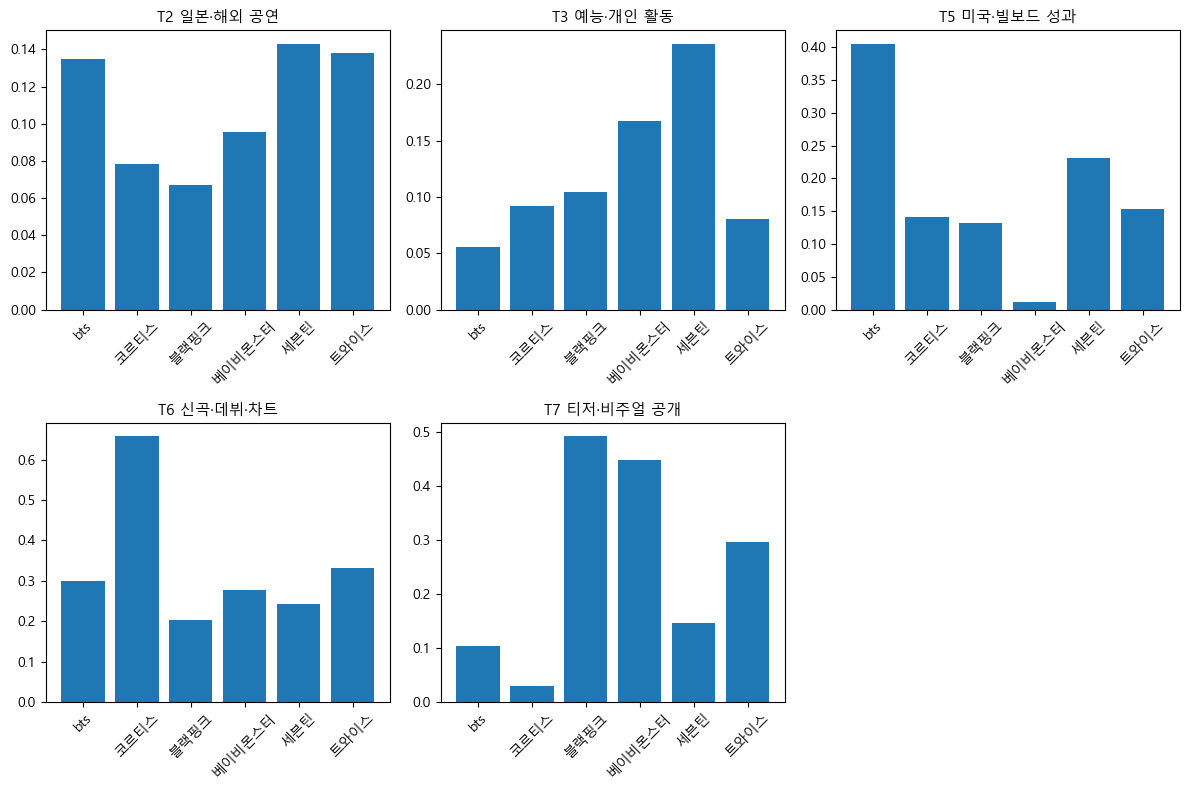

In [15]:
import matplotlib
%matplotlib inline
plt.rc('font', family='Malgun Gothic')

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for col, ax in zip(trend_use.columns, axes.ravel()):
    ax.set_title(col, fontsize=11)
    ax.tick_params(axis='x', rotation=45)
    ax.bar(trend_use.index, trend_use[col])
for ax in axes.flat[len(trend_use.columns):]:
    ax.remove()
plt.tight_layout()
plt.show()

In [16]:
cat = {
    'T2 일본·해외 공연': '해외 공연·투어',
    'T5 미국·빌보드 성과': '차트·판매 성과',
    'T6 신곡·데뷔·차트': '차트·판매 성과',
    'T3 예능·개인 활동': '멤버 개인 활동',
    'T7 티저·비주얼 공개': '컴백 홍보',
}
trend_cat = trend_use.T.groupby(cat).sum().T
trend_cat.round(3)

,멤버 개인 활동,차트·판매 성과,컴백 홍보,해외 공연·투어
group,,,,
bts,0.056,0.705,0.105,0.135
코르티스,0.092,0.799,0.030,0.078
블랙핑크,0.104,0.336,0.492,0.067
베이비몬스터,0.168,0.289,0.448,0.096
세븐틴,0.236,0.474,0.147,0.143
트와이스,0.081,0.485,0.296,0.138


In [17]:
from gensim.matutils import corpus2dense

dt = corpus2dense(model.get_document_topics(corpus, minimum_probability=0),
                  num_terms=num_topics).T
dt = pd.DataFrame(dt, columns=[f'Topic{i+1}' for i in range(num_topics)])

for t in ['Topic1', 'Topic4', 'Topic5', 'Topic6']:
    top = dt[t].nlargest(3).index
    print(f'=== {t} ===')
    print(ko.loc[top, ['group', 'title']].assign(prob=dt.loc[top, t].round(3)).to_string())
    print()

=== Topic1 ===
    group                                            title   prob
494   세븐틴                 하하→세븐틴 원우, 코로나19 확산세에 줄줄이 확진(종합)  0.997
493   세븐틴  세븐틴 원우, 코로나19 확진 “호시 접촉, PCR 검사 기다리는중”(공식입장 전문)  0.995
495   세븐틴         세븐틴 디에잇, 팀 내 7번째 코로나19 확진 “이상 증상 없어”(공식)  0.995

=== Topic4 ===
     group                                            title   prob
146    bts  방탄소년단 소속사 측 “사재기+사이비 의혹 사실무근, 루머 유포자 고소 완료”[공식]  0.998
147    bts             BTS 팬들, 전면광고 성명문 발표 “하이브, 아티스트 보호하라”  0.998
1040  코르티스       “차량에 GPS 부착하고 집요하게 미행” 코르티스, 법적 대응 경고 [전문]  0.998

=== Topic5 ===
   group                                          title   prob
73   bts     ‘신인상→빌보드 1위’ 방탄소년단, 말하는대로 이뤄낸 7년 성장史[뮤직와치]  0.998
96   bts       방탄소년단 亞가수 최초 美 AMA 대상, 계단식 성장 있었기에[뮤직와치]  0.998
17   bts  [뮤직와치]‘빌보드→유니세프→AMAs 뚫은’ 방탄소년단, 이쯤되면 국위선양 아이돌  0.998

=== Topic6 ===
     group                                   title   prob
682   트와이스  트와이스 “새로운 청량 트와이스 컴백, 성장 보여드릴게요”(일문일답)  0.999
1018  코르티스           TXT→올데프 코르티스 ‘KM

In [18]:
for t in ['Topic2', 'Topic3', 'Topic7']:
    top = dt[t].nlargest(3).index
    print(f'=== {t} ===')
    print(ko.loc[top, ['group', 'title']].assign(prob=dt.loc[top, t].round(3)).to_string())
    print()

=== Topic2 ===
    group                                        title   prob
416   세븐틴                    세븐틴 “5월 30일 일본 정식 데뷔”(공식)  0.996
406   세븐틴                열도 뒤흔든 세븐틴 일본 콘서트, 총 6만 관객 열광  0.995
621  트와이스  트와이스, 日 첫 아레나 투어 사이타마 공연 현장 ‘3만6천명 열광’[포토엔]  0.995

=== Topic3 ===
      group                                               title   prob
902  베이비몬스터  베몬 아사, 멤버 母 생일에 김치 담가 선물하는 요리 실력 “봄동 비빔밥도 만들어”(정희)  0.990
525     세븐틴                 세븐틴 준 주연 中 웹드라마 ‘독가동화’ 오늘(27일) 첫 공개  0.989
653    트와이스                              트와이스, 순백의 트퉁이들~[포토엔HD]  0.988

=== Topic7 ===
      group                                    title   prob
864  베이비몬스터          베이비몬스터, 미스터리 무드로 펼쳐낸 매혹적 아우라 예고  0.993
797  베이비몬스터  YG 신인 베이비몬스터 ‘BATTER UP’ 포스터 공개…비주얼합 완벽  0.993
903  베이비몬스터            베이비몬스터, 인형 비주얼 두번째 주자는 로라·파리타  0.993

